# Notebook 03 · Módulo 2: Clasificador de latidos

**Proyecto #7 · Detección de arritmias en tiempo real con TinyML**

**Pregunta:** dado **un latido**, ¿es una **extrasístole ventricular (V)** o no?

Es exactamente la "Tarea 2" del notebook de seguros, pero con latidos:

| Notebook de seguros | Este notebook |
|---|---|
| Cada fila = un cliente | Cada fila = **un latido** |
| Columnas: edad, salario... | Columnas: la **forma** del latido + sus **intervalos R–R** |
| Objetivo: ¿cobró el seguro? (sí/no) | Objetivo: ¿es **V**? (sí/no) |
| `train_test_split` al azar 70/30 | **DS1 para entrenar, DS2 para probar** (pacientes distintos) |
| Modelo dummy vs kNN | Modelo dummy vs kNN |
| F1 y matriz de confusión | F1, matriz de confusión, **sensibilidad**, **especificidad** y **PPV** |

| Lo que pide tu doctora | En este módulo |
|---|---|
| **Etiquetas** | El tipo de cada latido anotado en MIT-BIH, agrupado en clases AAMI |
| **Métricas** | Se, Sp, PPV y F1 **de la clase V** (no la exactitud: ~90 % de los latidos son normales) |
| **Validación** | Entre pacientes: DS1 → DS2. Opcional: INCART como base externa |

> El kNN es la **línea base**. Más adelante (al preparar el Arduino) se entrenará una red neuronal pequeña, y tendrá que **ganarle** a este kNN para justificar su uso.

In [1]:
%pip install -q wfdb numpy pandas scipy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import shutil

if not Path("ecg_comun.py").exists():
    entradas = Path("/kaggle/input")
    encontrados = list(entradas.rglob("ecg_comun.py")) if entradas.exists() else []
    if not encontrados:
        raise FileNotFoundError("No encuentro ecg_comun.py: agrégalo con Add Input (el dataset donde lo subiste)")
    shutil.copy(encontrados[0], "ecg_comun.py")
    print("✓ ecg_comun.py copiado desde", encontrados[0])
else:
    print("✓ ecg_comun.py ya está junto al notebook")


✓ ecg_comun.py copiado desde /kaggle/input/datasets/lourdesgarcagarfias/cinc2017-proyecto7/cinc2017-proyecto7/ecg_comun.py


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import ecg_comun as ec

DATOS = Path("datos")
plt.rcParams["figure.figsize"] = (12, 3.5)
plt.rcParams["axes.grid"] = True
ec.descargar_base("mitdb", DATOS / "mitdb")

Descargando mitdb en datos/mitdb (puede tardar varios minutos)...
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Genera

## 1. Decisiones de este notebook

Están todas juntas aquí arriba para que las cambies y vuelvas a correr. **Cada una debes poder justificarla.**

In [4]:
ANTES_S = 0.25      # segundos del latido ANTES del pico R (incluye la onda P)
DESPUES_S = 0.40    # segundos DESPUÉS del pico R (incluye la onda T)
DIEZMADO = 4        # tomamos 1 de cada 4 muestras: 360 Hz -> 90 Hz (menos números = modelo más pequeño)
USAR_RR_SIGUIENTE = True   # ¿usar el R–R que viene DESPUÉS del latido? Mejora el resultado,
                           # pero obliga a esperar al siguiente latido para decidir (más latencia).
FACTOR_SUBMUESTREO = 4     # al entrenar: por cada latido V, como máximo 4 latidos no-V
SEMILLA = 42

## 2. Convertir latidos en filas de una tabla

Para cada latido anotado:
1. Filtramos la señal (causal, 0.5–40 Hz).
2. Recortamos de 250 ms antes a 400 ms después del pico R y lo **normalizamos** (le quitamos la mediana y lo dividimos entre su desviación estándar). Así no importa si un paciente tiene la señal más grande que otro.
3. Calculamos 5 números de **R–R**: el anterior, el siguiente, el promedio de los últimos 10, y dos razones (anterior/promedio y siguiente/anterior). Una V suele llegar **antes** (razón < 1) y dejar una **pausa** después.

Los latidos de clase **Q** (marcapasos / no clasificables) se descartan, como recomienda AAMI.

In [5]:
def latidos_a_tabla(x, fs, r, simbolos, registro):
    # Lleva todo a 360 Hz (por si viene de otra base)
    if fs != ec.FS:
        x = ec.remuestrear(x, fs, ec.FS)
        r = ec.remuestrear_posiciones(r, fs, ec.FS)
    limpia = ec.filtrar(x, ec.FS)
    a, b = int(ANTES_S * ec.FS), int(DESPUES_S * ec.FS)

    rr = np.diff(r) / ec.FS
    acumulado = np.concatenate([[0], np.cumsum(rr)])
    idx = np.arange(1, len(r) - 1)                          # necesitamos un latido antes y uno después
    clases = np.array([ec.AAMI[s] for s in simbolos])
    validos = (r[idx] - a >= 0) & (r[idx] + b < len(limpia)) & (clases[idx] != "Q")
    idx = idx[validos]

    # Forma del latido
    ventanas = r[idx][:, None] + np.arange(-a, b, DIEZMADO)[None, :]
    forma = limpia[ventanas]
    forma = (forma - np.median(forma, axis=1, keepdims=True)) / (forma.std(axis=1, keepdims=True) + 1e-6)

    # Intervalos R–R
    rr_ant = rr[idx - 1]
    rr_sig = rr[idx]
    inicio = np.maximum(0, idx - 10)
    rr_prom = (acumulado[idx] - acumulado[inicio]) / (idx - inicio)
    rr_feats = np.column_stack([rr_ant, rr_sig, rr_prom, rr_ant / rr_prom, rr_sig / rr_ant])
    if not USAR_RR_SIGUIENTE:
        rr_feats = rr_feats[:, [0, 2, 3]]
    return forma, rr_feats, clases[idx], np.full(len(idx), registro)


def construir(registros, carpeta=DATOS / "mitdb", canal="MLII", ext="atr"):
    partes = [latidos_a_tabla(*ec.leer_senal(carpeta, n, canal)[:2], *ec.leer_latidos(carpeta, n, ext), n)
              for n in registros]
    forma, rr, clases, regs = (np.concatenate(p) for p in zip(*partes))
    return {"forma": forma, "rr": rr, "clase": clases, "registro": regs, "y": (clases == "V").astype(int)}


ds1 = construir(ec.DS1)
ds2 = construir(ec.DS2)
for nombre, d in [("DS1 (entrenar)", ds1), ("DS2 (probar)", ds2)]:
    print(f"{nombre}: {len(d['y'])} latidos · {d['forma'].shape[1]} números de forma + {d['rr'].shape[1]} de R–R"
          f" · V = {d['y'].sum()} ({100 * d['y'].mean():.1f} %)")
display(pd.crosstab(np.concatenate([np.full(len(ds1["y"]), "DS1"), np.full(len(ds2["y"]), "DS2")]),
                    np.concatenate([ds1["clase"], ds2["clase"]]), margins=True))

DS1 (entrenar): 50969 latidos · 59 números de forma + 5 de R–R · V = 3788 (7.4 %)
DS2 (probar): 49661 latidos · 59 números de forma + 5 de R–R · V = 3219 (6.5 %)


col_0,F,N,S,V,All
row_0,,,,,
DS1,414,45824,943,3788,50969
DS2,388,44218,1836,3219,49661
All,802,90042,2779,7007,100630


**Cómo leerlo:** cada latido se convirtió en una fila con ~60 números de forma y 5 de R–R. Es la misma idea que la tabla de clientes, solo que con más columnas.

## 3. ¿Cómo se ve cada clase? (promedio de DS1)

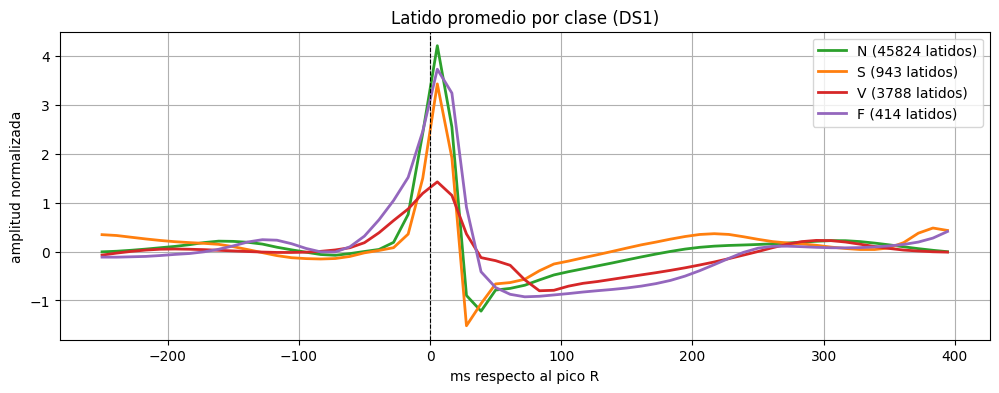

,R–R anterior,R–R siguiente,R–R promedio,anterior/promedio,siguiente/anterior
clase,,,,,
F,0.586,0.464,0.610,0.966,0.799
N,0.756,0.736,0.739,1.002,0.993
S,0.494,0.644,0.626,0.818,1.217
V,0.519,0.861,0.685,0.733,1.673


In [6]:
t_ms = 1000 * np.arange(-int(ANTES_S * ec.FS), int(DESPUES_S * ec.FS), DIEZMADO) / ec.FS
plt.figure(figsize=(12, 4))
for clase, color in [("N", "tab:green"), ("S", "tab:orange"), ("V", "tab:red"), ("F", "tab:purple")]:
    sel = ds1["clase"] == clase
    if sel.sum():
        plt.plot(t_ms, ds1["forma"][sel].mean(axis=0), color=color, lw=2, label=f"{clase} ({sel.sum()} latidos)")
plt.axvline(0, color="k", ls="--", lw=0.8)
plt.xlabel("ms respecto al pico R"); plt.ylabel("amplitud normalizada"); plt.legend()
plt.title("Latido promedio por clase (DS1)")
plt.show()

nombres_rr = ["R–R anterior", "R–R siguiente", "R–R promedio", "anterior/promedio", "siguiente/anterior"]
if not USAR_RR_SIGUIENTE:
    nombres_rr = [nombres_rr[i] for i in (0, 2, 3)]
tabla_rr = pd.DataFrame(ds1["rr"], columns=nombres_rr).assign(clase=ds1["clase"])
display(tabla_rr.groupby("clase").median().round(3))

**Cómo leerlo:** ver en la columna **anterior/promedio**: en N es cercana a 1 (el latido llegó a tiempo); en S y V es menor que 1 (llegó **antes**). Y **siguiente/anterior** en V suele ser mayor que 1 (la **pausa compensadora**).

## 4. Cómo vamos a medir

Igual que en el notebook guía, con una **matriz de confusión** (filas = lo real, columnas = lo que dijo el modelo), pero ahora calculamos las métricas que pediste en tu hipótesis:

- **Sensibilidad (Se)** = de las V reales, ¿cuántas detecté? → meta ≥ 90 %
- **Especificidad (Sp)** = de los no-V reales, ¿cuántos dije correctamente que no eran V? → meta ≥ 90 %
- **PPV** = de las veces que dije "V", ¿cuántas eran V de verdad? (si es bajo, hay muchas falsas alarmas)
- **F1** = un resumen de Se y PPV

In [7]:
def evaluar(y_real, y_pred, titulo="", graficar=True):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    m = {
        "Se %": 100 * vp / (vp + fn) if vp + fn else np.nan,
        "Sp %": 100 * vn / (vn + fp) if vn + fp else np.nan,
        "PPV %": 100 * vp / (vp + fp) if vp + fp else 0.0,
        "F1": f1_score(y_real, y_pred, zero_division=0),
    }
    if graficar:
        plt.figure(figsize=(4, 3.2))
        sns.heatmap([[vn, fp], [fn, vp]], annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=["dijo no-V", "dijo V"], yticklabels=["real no-V", "real V"])
        plt.grid(False); plt.title(titulo); plt.show()
    print(f"{titulo}:  Se = {m['Se %']:.1f} %   Sp = {m['Sp %']:.1f} %   PPV = {m['PPV %']:.1f} %   F1 = {m['F1']:.2f}")
    return m

## 5. Modelo dummy (la línea base mínima)

Igual que en la guía: un modelo que **no mira el latido**. Probamos dos:
- **"Siempre no-V"**: dice que todos son normales.
- **"Al azar"**: dice "V" con la misma probabilidad con la que aparecen las V en DS1.

In [8]:
X1 = np.hstack([ds1["forma"], ds1["rr"]]); y1 = ds1["y"]; g1 = ds1["registro"]
X2 = np.hstack([ds2["forma"], ds2["rr"]]); y2 = ds2["y"]

resultados = {}
for estrategia, nombre in [("most_frequent", "Dummy: siempre no-V"), ("stratified", "Dummy: al azar")]:
    dummy = DummyClassifier(strategy=estrategia, random_state=SEMILLA).fit(X1, y1)
    pred = dummy.predict(X2)
    print(f"   exactitud = {100 * (pred == y2).mean():.1f} %  ← parece buena, pero...")
    resultados[nombre] = evaluar(y2, pred, nombre, graficar=False)

   exactitud = 93.5 %  ← parece buena, pero...
Dummy: siempre no-V:  Se = 0.0 %   Sp = 100.0 %   PPV = 0.0 %   F1 = 0.00
   exactitud = 87.0 %  ← parece buena, pero...
Dummy: al azar:  Se = 7.5 %   Sp = 92.5 %   PPV = 6.5 %   F1 = 0.07


**Cómo leerlo:** "siempre no-V" tiene una **exactitud** altísima pero **Se = 0 %**: nunca encuentra una extrasístole. Por eso **nunca** reportes solo la exactitud.

## 6. Elegir k sin hacer trampa (validación cruzada **por paciente**)

En la guía se probó k = 1…10 mirando directamente el conjunto de prueba. Eso es una pequeña trampa: elegimos el k que mejor le va **a la prueba**. Lo correcto es elegir k **solo con DS1**:

1. Partimos DS1 en 5 grupos **de pacientes** (`GroupKFold`): cada paciente cae en un solo grupo.
2. Entrenamos con 4 grupos y medimos en el quinto. Repetimos 5 veces.
3. Elegimos el k con mejor F1 promedio. **DS2 no se toca** hasta el final.

Además **submuestreamos**: al entrenar dejamos todas las V y como máximo 4 no-V por cada V. Así el modelo no se ahoga en latidos normales y kNN corre más rápido.

,k,F1 promedio,F1 desviación
0,1,0.473,0.193
1,3,0.485,0.121
2,5,0.483,0.155
3,9,0.520,0.111
4,15,0.535,0.088
5,25,0.538,0.118


k elegido: 25


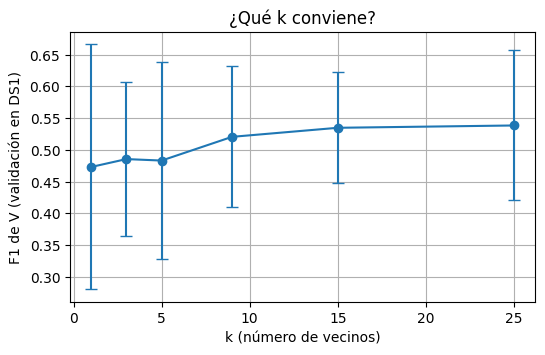

In [9]:
rng = np.random.default_rng(SEMILLA)

def submuestrear(indices, y):
    v = indices[y[indices] == 1]
    no_v = indices[y[indices] == 0]
    cuantos = min(len(no_v), FACTOR_SUBMUESTREO * max(len(v), 1))
    return np.concatenate([v, rng.choice(no_v, size=cuantos, replace=False)])

def validacion_por_paciente(X, y, grupos, k, n_grupos=5):
    f1s = []
    for entrena, valida in GroupKFold(n_splits=n_grupos).split(X, y, grupos):
        entrena = submuestrear(entrena, y)
        modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
        modelo.fit(X[entrena], y[entrena])
        f1s.append(f1_score(y[valida], modelo.predict(X[valida]), zero_division=0))
    return np.mean(f1s), np.std(f1s)

valores_k = [1, 3, 5, 9, 15, 25]
cv = pd.DataFrame([(k, *validacion_por_paciente(X1, y1, g1, k)) for k in valores_k],
                  columns=["k", "F1 promedio", "F1 desviación"])
display(cv.round(3))
mejor_k = int(cv.sort_values("F1 promedio").k.iloc[-1])
print("k elegido:", mejor_k)

plt.figure(figsize=(6, 3.5))
plt.errorbar(cv.k, cv["F1 promedio"], yerr=cv["F1 desviación"], fmt="o-", capsize=4)
plt.xlabel("k (número de vecinos)"); plt.ylabel("F1 de V (validación en DS1)")
plt.title("¿Qué k conviene?"); plt.show()

**Cómo leerlo:** la barra de error muestra cuánto cambia el F1 entre grupos de pacientes. Si es grande, el modelo funciona muy distinto según el paciente; eso es normal en ECG y es justo lo que la validación por paciente deja ver.

## 7. ¿Qué información sirve más: la forma o los R–R?

In [10]:
n_forma = ds1["forma"].shape[1]
conjuntos = {"solo forma": slice(0, n_forma), "solo R–R": slice(n_forma, None), "forma + R–R": slice(None)}
filas = []
for nombre, cols in conjuntos.items():
    media, desv = validacion_por_paciente(X1[:, cols], y1, g1, mejor_k)
    filas.append({"columnas usadas": nombre, "F1 promedio": round(media, 3), "F1 desviación": round(desv, 3)})
display(pd.DataFrame(filas))

,columnas usadas,F1 promedio,F1 desviación
0,solo forma,0.477,0.148
1,solo R–R,0.538,0.283
2,forma + R–R,0.521,0.128


## 8. Prueba final en DS2 (pacientes que el modelo **nunca vio**)

Entrenamos con **todo DS1** (submuestreado) y probamos **una sola vez** en DS2. Este es el número que va en tu reporte.

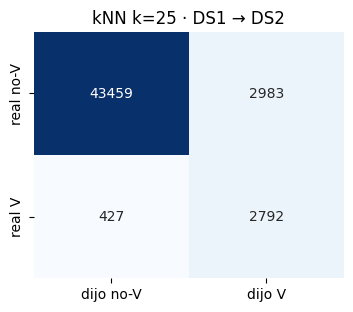

kNN k=25 · DS1 → DS2:  Se = 86.7 %   Sp = 93.6 %   PPV = 48.3 %   F1 = 0.62


,Se %,Sp %,PPV %,F1
Dummy: siempre no-V,0.00,100.00,0.00,0.00
Dummy: al azar,7.52,92.54,6.53,0.07
kNN (k=25) · DS1 → DS2,86.74,93.58,48.35,0.62


In [11]:
entrena = submuestrear(np.arange(len(y1)), y1)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)).fit(X1[entrena], y1[entrena])
pred2 = knn.predict(X2)
resultados[f"kNN (k={mejor_k}) · DS1 → DS2"] = evaluar(y2, pred2, f"kNN k={mejor_k} · DS1 → DS2")
display(pd.DataFrame(resultados).T.round(2))

### 8.1 ¿Con qué confunde las V?

Desglosamos por la clase AAMI real: ¿qué porcentaje de cada clase etiquetó como V?

In [12]:
desglose = pd.DataFrame({"clase real": ds2["clase"], "dijo V": pred2})
tabla_desglose = desglose.groupby("clase real")["dijo V"].agg(latidos="count", dijo_V="sum")
tabla_desglose["% que dijo V"] = (100 * tabla_desglose.dijo_V / tabla_desglose.latidos).round(1)
display(tabla_desglose)

,latidos,dijo_V,% que dijo V
clase real,,,
F,388,14,3.6
N,44218,1733,3.9
S,1836,1236,67.3
V,3219,2792,86.7


**Cómo leerlo:** para la fila **V** quieres un porcentaje alto (es la sensibilidad). Para **N** y **S**, uno bajo (son falsas alarmas). La clase **F** (fusión) es mitad normal y mitad ventricular, así que es normal que el modelo dude.

### 8.2 ¿Funciona igual en todos los pacientes?

,registro,V reales,Se %,falsas alarmas
0,105,41,14.6,62
1,200,825,93.2,1
2,202,19,94.7,32
3,210,195,79.0,12
4,213,220,70.9,23
5,214,256,85.5,65
6,219,64,93.8,15
7,221,396,100.0,0
8,228,362,90.1,17
9,233,830,81.7,12


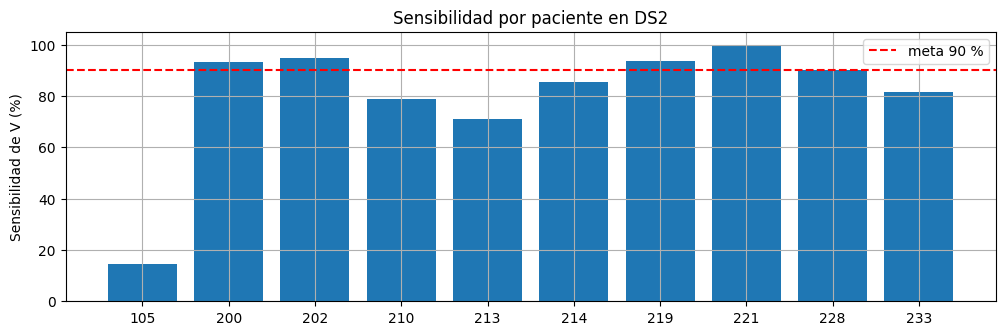

In [13]:
por_paciente = []
for reg in ec.DS2:
    sel = ds2["registro"] == reg
    if ds2["y"][sel].sum() >= 10:                      # solo pacientes con al menos 10 V
        yt, yp = ds2["y"][sel], pred2[sel]
        por_paciente.append({"registro": reg, "V reales": int(yt.sum()),
                             "Se %": round(100 * (yp[yt == 1] == 1).mean(), 1),
                             "falsas alarmas": int(((yp == 1) & (yt == 0)).sum())})
por_paciente = pd.DataFrame(por_paciente)
display(por_paciente)
plt.figure()
plt.bar(por_paciente.registro, por_paciente["Se %"])
plt.axhline(90, color="red", ls="--", label="meta 90 %")
plt.ylabel("Sensibilidad de V (%)"); plt.legend(); plt.title("Sensibilidad por paciente en DS2")
plt.show()

## 9.  ¿qué pasa si mezclamos pacientes?

Para que con datos propios, se pueda observar por qué los papers que **no separan pacientes** reportan números tan altos, hacemos lo mismo que el notebook de seguros: juntamos todos los latidos y los partimos **al azar** 70/30.

In [14]:
X_todo = np.vstack([X1, X2]); y_todo = np.concatenate([y1, y2])
Xa, Xb, ya, yb = train_test_split(X_todo, y_todo, test_size=0.3, random_state=SEMILLA, stratify=y_todo)
ia = submuestrear(np.arange(len(ya)), ya)
trampa = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=mejor_k)).fit(Xa[ia], ya[ia])
resultados["kNN · latidos mezclados al azar (TRAMPA)"] = evaluar(yb, trampa.predict(Xb), "Mezclando pacientes (trampa)", graficar=False)
display(pd.DataFrame(resultados).T.round(2))

Mezclando pacientes (trampa):  Se = 96.7 %   Sp = 99.3 %   PPV = 91.2 %   F1 = 0.94


,Se %,Sp %,PPV %,F1
Dummy: siempre no-V,0.00,100.00,0.00,0.00
Dummy: al azar,7.52,92.54,6.53,0.07
kNN (k=25) · DS1 → DS2,86.74,93.58,48.35,0.62
kNN · latidos mezclados al azar (TRAMPA),96.67,99.31,91.24,0.94


**Cómo leerlo:** al mezclar, el modelo ve latidos **del mismo paciente** al entrenar y al probar, y saca números mucho mejores. Pero eso **no** dice nada de cómo funcionará con una persona nueva (que es lo que pasará con el Arduino). el número honesto es el de **DS1 → DS2**.

## 10. (Opcional) Validación externa con INCART

INCART es otra base (Rusia, 257 Hz, 12 derivaciones). Probar ahí, **sin reentrenar**, muestra si el modelo aguanta otro hospital y otro aparato. Pesa **~800 MB**; cambia `USAR_INCART` a `True` cuando quieras correrlo.

In [15]:
USAR_INCART = False

if USAR_INCART:
    ec.descargar_base("incartdb", DATOS / "incartdb")
    inc = construir(ec.listar_registros(DATOS / "incartdb"), carpeta=DATOS / "incartdb", canal="II")
    X3 = np.hstack([inc["forma"], inc["rr"]])
    resultados["kNN · DS1 → INCART"] = evaluar(inc["y"], knn.predict(X3), "kNN · DS1 → INCART")
    display(pd.DataFrame(resultados).T.round(2))
else:
    print("INCART desactivado (cambia USAR_INCART = True para correrlo)")

INCART desactivado (cambia USAR_INCART = True para correrlo)
